In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    "text.usetex": False,          
    "font.family": "serif",
    "mathtext.fontset": "cm",     
})

In [2]:
# ========== Load the unified results file ==========
results_dir = "../Results/Adder" 
result_files = sorted([f for f in os.listdir(results_dir) if f.startswith("results") and f.endswith(".pkl")])
latest_result_file = os.path.join(results_dir, result_files[-1])

with open(latest_result_file, "rb") as f:
    all_results = pickle.load(f)

In [3]:
# ========== Load cutting results file ==========
n_cut = 3 
file_cutting = "results12172142.pkl"     # n_cut=3

file_cutting_full_path = os.path.join(results_dir, file_cutting)
with open(file_cutting_full_path, "rb") as f:
    all_results_cutting = pickle.load(f)

In [4]:
all_results_cutting

{(5, np.float64(1e-07), 'x'): {'depth': 237,
  'num_gates': 237,
  'num_circuit_partitions': 23,
  'n_cut': 3,
  'gamma_b2': np.float64(0.6264283807336661),
  'gamma_b4': np.float64(1.2230917685853762),
  'worst_case_fidelity_bound_b2': np.float64(0.9999999997795775),
  'worst_case_fidelity_bound_b4': np.float64(0.9999999991597217)},
 (5, np.float64(1.7782794100389227e-07), 'x'): {'depth': 237,
  'num_gates': 237,
  'num_circuit_partitions': 23,
  'n_cut': 3,
  'gamma_b2': np.float64(0.6264283807336661),
  'gamma_b4': np.float64(1.2230917685853762),
  'worst_case_fidelity_bound_b2': np.float64(0.9999999993029425),
  'worst_case_fidelity_bound_b4': np.float64(0.9999999973427668)},
 (5, np.float64(3.162277660168379e-07), 'x'): {'depth': 237,
  'num_gates': 237,
  'num_circuit_partitions': 23,
  'n_cut': 3,
  'gamma_b2': np.float64(0.6264283807336661),
  'gamma_b4': np.float64(1.2230917685853762),
  'worst_case_fidelity_bound_b2': np.float64(0.9999999977955956),
  'worst_case_fidelity_bou

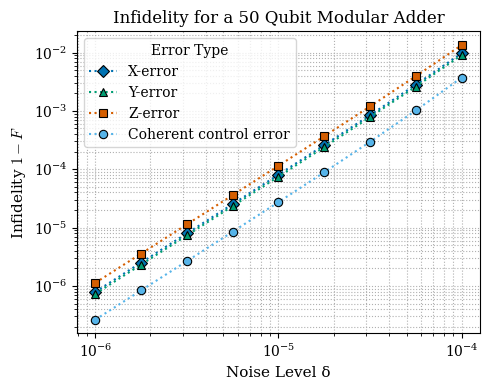

In [5]:
data_to_plot = {}
error_types = ["x", "y", "z", "coherent_control"]
n_qubits = [25]

colors = ["#0072B2", "#009E73", "#56B4E9", "#D55E00"]


# Mapping for styling
error_labels = {
    "x": "X-error",
    "y": "Y-error",
    "z": "Z-error",
    "coherent_control": "Coherent control error",
}

error_colors = {
    "x": colors[0],
    "y": colors[1],
    "z": colors[3],
    "coherent_control": colors[2],
}

error_markers = {
    "x": "D",
    "y": "^",
    "z": "s",
    "coherent_control": "o",
}



for n_q in n_qubits:
    for error in error_types:
        deltas = []
        infidelities = []
        
        # Iterate through all_results keys (n_q, delt, err) and values (results dict)
        for (n, delt, err), results in all_results_cutting.items():
            if err == error and n == n_q:
                # filter delta values between 1e-6 and 1e-4
                if not (1e-6 <= delt <= 1e-4):
                    continue
                # Calculate Infidelity: 1 - Fidelity
                infidelity = 1.0 - results.get("worst_case_fidelity_bound_b2", 0.0) 
                deltas.append(delt)
                infidelities.append(infidelity)
                
        if deltas:
            # Convert to numpy arrays
            deltas = np.array(deltas)
            infidelities = np.array(infidelities)
            
            # Sort data by delta value for a clean plot
            sort_indices = np.argsort(deltas)
            data_to_plot[error] = {
                'delta': deltas[sort_indices],
                'infidelity': infidelities[sort_indices]
            }

    plt.figure(figsize=(5, 4))

    for error, data in data_to_plot.items():
        label = error_labels.get(error, error)
        color = error_colors.get(error, None)
        marker = error_markers.get(error, "o")
        # plt.plot(data['delta'], data['infidelity'], marker=marker, linestyle='-', label=label, color=color, alpha=1.0)
        plt.plot(data['delta'], data['infidelity'],linestyle='dotted', marker=marker, label=label, color=color, alpha=1.0, markerfacecolor=color, markeredgecolor="black", markeredgewidth=0.8)
    # Set both axes to log scale for clarity, as delta is log-spaced
    plt.xscale('log')
    plt.yscale('log')

    plt.xlabel("Noise Level δ", fontsize=11)
    plt.ylabel("Infidelity $1 - F$", fontsize=11)
    plt.title(f'Infidelity for a {n_q*2} Qubit Modular Adder', fontsize=12)
    plt.legend(title='Error Type', loc='upper left')
    plt.grid(True, which="both", ls=":")
    plt.tight_layout()
    plt.savefig(f'Adder_Worst_Case_Infidelity_vs_Noise_Level_{2*n_q}_Qubits_cutting_{n_cut}.pdf')

In [ ]:
# ========== Load different cutting results file ==========
file_different_cut = "results12221027.pkl"

file_different_cut_full_path = os.path.join(results_dir, file_different_cut)
with open(file_different_cut_full_path, "rb") as f:
    all_results_different_cut = pickle.load(f)

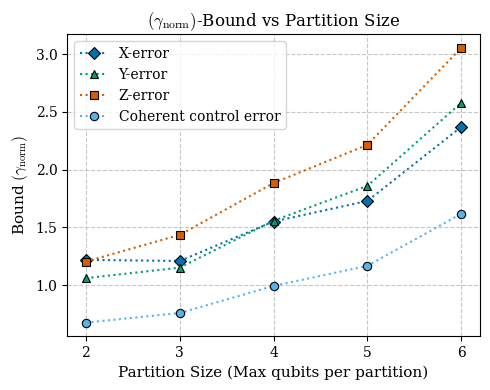

In [7]:
n_qubits_val = 25  # We are interested in n_q = 25
delta_val = 1e-7   # Pick a specific delta to plot gamma_b4 vs n_cut
error_types = ["x", "y", "z", "coherent_control"]


plt.figure(figsize=(5, 4))

for error_type in error_types:
    # Filter results for this specific error and delta
    # We need to extract (n_cut, gamma_b4) pairs
    plot_points = []
    
    for key, results in all_results_different_cut.items():
        k_nq, k_delta, k_error, k_ncut = key
        
        # Match the specific experiment parameters
        if k_nq == n_qubits_val and k_error == error_type and np.isclose(k_delta, delta_val):
            # We group by n_cut. Since multiple deltas exist for one n_cut, 
            # and gamma_b4 depends on the circuit structure (n_cut), 
            # we just need one delta's entry per n_cut.
            
            plot_points.append((k_ncut, results['gamma_b4']))

    # Sort by n_cut so the line connects correctly
    plot_points.sort(key=lambda x: x[0])
    
    if plot_points:
        n_cuts = [p[0] for p in plot_points]
        gammas = [p[1] for p in plot_points]
        
        plt.plot(n_cuts, gammas, marker=error_markers.get(error_type, "o"), label=error_labels.get(error_type, error_type), color=error_colors.get(error_type), markerfacecolor=error_colors.get(error_type), markeredgecolor="black", markeredgewidth=0.8,linestyle='dotted')

# 3. Formatting the plot
plt.title(r'$(\gamma_{\mathrm{norm}})$-Bound vs Partition Size', fontsize=12)
plt.xlabel('Partition Size (Max qubits per partition)', fontsize=11)
plt.ylabel(r"Bound $(\gamma_{\mathrm{norm}})$", fontsize=11)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# Save or show
plt.tight_layout()
plt.savefig(f"Adder_Gamma_norm_vs_Partition_Size.pdf")